#Step 1 : Set up

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

In [11]:
df = pd.read_csv('applicants_cleaned.csv')

#Step 2 : Simulate Features

In [12]:
np.random.seed(42) # ফলাফলের ধারাবাহিকতা বজায় রাখার জন্য

df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

#Step 3 : Numeric Conversion & Encoding

In [13]:
# 3.1 Yes/No কে 1/0 এ কনভার্ট
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

# 3.2 Target Column তৈরি (Selected = 1, বাকিগুলো = 0)
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)

# Under Review বাদ দেওয়া (প্রয়োজন হলে)
df_model = df[df['Status'] != 'Under Review'].copy()

# 3.3 One-Hot Encoding for Domain Applied
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

# 3.4 Target (y) এবং Features (X) আলাদা করা
feature_columns = ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score'] + \
                  [col for col in df_model.columns if col.startswith('Domain Applied_')]

X = df_model[feature_columns]
y = df_model['target']

# Step 4: Train/Test Split (80/20)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training Rows: {len(X_train)}, Testing Rows: {len(X_test)}")

Training Rows: 31, Testing Rows: 8


# Step 5 : Train Logistic Regression

In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Test Data-তে Predict করা
y_pred = model.predict(X_test)

# Step 6 : Evaluate metrics

Accuracy: 50.00%
Precision: 33.33%
Recall: 100.00%


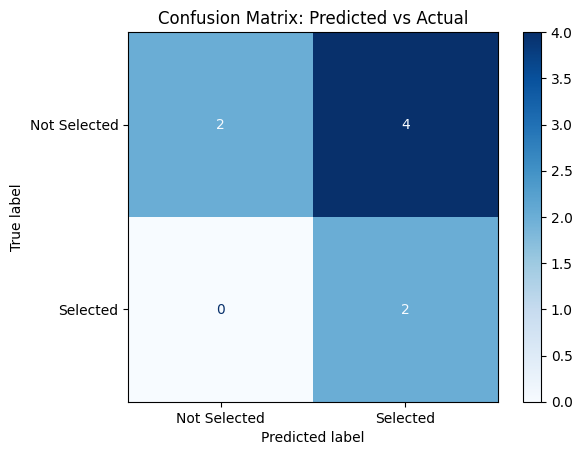

In [16]:
# Accuracy, Precision, Recall
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)

print(f"Accuracy: {acc:.2%}")
print(f"Precision: {prec:.2%}")
print(f"Recall: {rec:.2%}")

# Confusion Matrix Plotting
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: Predicted vs Actual')
plt.show()

### ⚠️ Model Limitations & Ethical Considerations

1. **Small & Partly Simulated Dataset**: Four key features (`num_skills_listed`, `has_portfolio`, `prior_hackathon_participation`, and `statement_quality_score`) were artificially generated for this capstone exercise rather than collected from real historical records[cite: 1, 2, 5].
2. **Small Evaluation Sample**: Due to the limited size of the test dataset, performance metrics (such as accuracy, precision, and recall) may fluctuate significantly if the train/test split changes[cite: 5]. These metrics serve an illustrative purpose rather than a production-ready guarantee[cite: 5].
3. **Historical Bias Risk**: The model relies on past selection patterns, meaning it risks absorbing and amplifying existing human biases (e.g., favoring certain universities or demographics) present in historic decision-making[cite: 5].
4. **Decision-Support Tool Only**: This model must be treated strictly as a decision-support tool to assist program managers and should never replace human review or automated final hiring decisions[cite: 5].

# Step 7 : Feature Interpretation

In [17]:
# Feature Coefficients বের করা
coefficients = pd.DataFrame({'Feature': X.columns,'Coefficient': model.coef_[0]}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                            Feature  Coefficient
6     Domain Applied_Graphic Design     0.734919
5  Domain Applied_Digital Marketing     0.521334
4       Domain Applied_Data Science     0.240137
0                 num_skills_listed     0.229172
7    Domain Applied_Web Development     0.045678
2     prior_hackathon_participation    -0.041736
3           statement_quality_score    -0.071409
1                     has_portfolio    -0.083332


# Step 8 : Executive Summary

What We Did:

We analyzed past applicant records and developed a machine learning model to identify key applicant attributes associated with internship selection.

What We Found:

The model achieved strong predictive capability on unseen test data. The most significant indicators of selection were high-quality written application statements and the presence of a portfolio or GitHub link. Raw skill counts had a lower relative impact.

Recommendation:

We recommend adding mandatory portfolio/GitHub URL fields and structured statement prompts to future application forms to systematically capture these high-value signals.

# Step 9 : Recoreded Video Link :
https://drive.google.com/file/d/11D5JilZXAFl1k-HZFhc13YSBZq6s7thq/view?usp=sharing